# Weak Supervision for SMS Spam, Part 2: Data Augmentation

Here I make a labeled training set bigger with **transformation functions (TFs)**. A TF takes one message and returns a slightly changed copy that should keep the same label. Snorkel applies TFs through a **policy** that decides which TFs to chain together for each message.

Like the original augmentation tutorial, this notebook starts from an already labeled training set (the real labels of the train split), so the effect of augmentation isn't mixed up with label noise from part 1.

Plan:
1. Load the data
2. Write TFs: the original's WordNet synonym swaps plus three SMS-specific ones
3. Apply them with a policy
4. Train models with and without augmentation and compare on the test set

In [1]:
import os
import random
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["PYTHONHASHSEED"] = "0"

import numpy as np
import pandas as pd

np.random.seed(0)
random.seed(0)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)

In [2]:
from utils import download_nlp_resources

download_nlp_resources()

## 1. Loading the data

Same splits as part 1. This time I load the train labels, and only use train and test.

In [3]:
from utils import load_spam_dataset

df_train, df_test = load_spam_dataset(load_train_labels=True)

Y_train = df_train.label.values
Y_test = df_test.label.values

print(f"train: {len(df_train)} messages, {Y_train.mean():.1%} spam")
print(f"test:  {len(df_test)} messages, {Y_test.mean():.1%} spam")

train: 3619 messages, 12.6% spam
test:  1035 messages, 12.7% spam


## 2. Writing transformation functions

A TF is a plain Python function wrapped with `@transformation_function`. It gets one data point, changes it, and returns it. If it can't do anything useful it returns `None`, and Snorkel skips it. The working assumption is that these small edits don't change whether a message is spam.

### Synonym replacement (kept from the original)

These three are the original lab's TFs. spaCy tags each token's part of speech and WordNet supplies a synonym for one random verb, noun or adjective.

In [4]:
import nltk
from nltk.corpus import wordnet as wn
from snorkel.augmentation import transformation_function
from snorkel.preprocess.nlp import SpacyPreprocessor

spacy = SpacyPreprocessor(text_field="text", doc_field="doc", memoize=True)


def get_synonym(word, pos=None):
    synsets = wn.synsets(word, pos=pos)
    if synsets:
        words = [lemma.name() for lemma in synsets[0].lemmas()]
        if words[0].lower() != word.lower():
            return words[0].replace("_", " ")


def replace_token(doc, idx, replacement):
    return " ".join([doc[:idx].text, replacement, doc[1 + idx :].text])


def replace_pos_with_synonym(x, spacy_pos, wordnet_pos):
    idxs = [i for i, token in enumerate(x.doc) if token.pos_ == spacy_pos]
    if idxs:
        idx = np.random.choice(idxs)
        synonym = get_synonym(x.doc[idx].text, pos=wordnet_pos)
        if synonym:
            x.text = replace_token(x.doc, idx, synonym)
            return x


@transformation_function(pre=[spacy])
def replace_verb_with_synonym(x):
    return replace_pos_with_synonym(x, "VERB", "v")


@transformation_function(pre=[spacy])
def replace_noun_with_synonym(x):
    return replace_pos_with_synonym(x, "NOUN", "n")


@transformation_function(pre=[spacy])
def replace_adjective_with_synonym(x):
    return replace_pos_with_synonym(x, "ADJ", "a")

### New SMS-specific TFs

Synonyms fit regular English, but SMS has its own kind of variation. Three new TFs:

- `swap_abbreviation` switches one texting abbreviation: you/u, to/2, your/ur, are/r. The u, ur and r forms also switch back to the long word. I left out 2 back to "to", because it would also hit prices like £2.
- `add_typo` swaps, drops or repeats one letter inside a word, since SMS is full of typos.
- `replace_number` replaces a number with random digits of the same length. It keeps the first digit, so a number starting with 0 still looks like a phone number.

I dropped the original's `change_person` and `swap_adjectives`: SMS rarely names people or has two adjectives in one message, so they would mostly return `None`.

In [5]:
import re

ABBREVIATIONS = {"you": "u", "to": "2", "your": "ur", "are": "r", "u": "you", "ur": "your", "r": "are"}
ABBREVIATION_RE = re.compile(r"\b(" + "|".join(ABBREVIATIONS) + r")\b", flags=re.I)


@transformation_function()
def swap_abbreviation(x):
    matches = list(ABBREVIATION_RE.finditer(x.text))
    if matches:
        m = matches[np.random.randint(len(matches))]
        x.text = x.text[: m.start()] + ABBREVIATIONS[m.group().lower()] + x.text[m.end() :]
        return x


@transformation_function()
def add_typo(x):
    matches = list(re.finditer(r"[A-Za-z]{4,}", x.text))
    if matches:
        m = matches[np.random.randint(len(matches))]
        word = m.group()
        i = np.random.randint(1, len(word) - 1)
        kind = np.random.choice(["swap", "drop", "repeat"])
        if kind == "swap":
            word = word[:i] + word[i + 1] + word[i] + word[i + 2 :]
        elif kind == "drop":
            word = word[:i] + word[i + 1 :]
        else:
            word = word[:i] + word[i] + word[i:]
        x.text = x.text[: m.start()] + word + x.text[m.end() :]
        return x


@transformation_function()
def replace_number(x):
    matches = list(re.finditer(r"\d+", x.text))
    if matches:
        m = matches[np.random.randint(len(matches))]
        old = m.group()
        if len(old) == 1:
            new = str(np.random.choice([d for d in range(10) if str(d) != old]))
        else:
            new = old[0] + "".join(str(d) for d in np.random.randint(0, 10, len(old) - 1))
        x.text = x.text[: m.start()] + new + x.text[m.end() :]
        return x

In [6]:
tfs = [
    replace_verb_with_synonym,
    replace_noun_with_synonym,
    replace_adjective_with_synonym,
    swap_abbreviation,
    add_typo,
    replace_number,
]

`preview_tfs` shows the first message each TF manages to change.

In [7]:
from utils import preview_tfs

preview_tfs(df_train, tfs)

,TF Name,Original Text,Transformed Text
0,replace_verb_with_synonym,I'm in office now da:)where are you?,I'm in office now da:)where be you?
1,replace_noun_with_synonym,"Faith makes things possible,Hope makes things work,Love makes things beautiful,May you have all three this Christmas...","religion makes things possible,Hope makes things work,Love makes things beautiful,May you have all three this Chris..."
2,replace_adjective_with_synonym,Aiyo u so poor thing... Then u dun wan 2 eat? U bathe already?,Aiyo u so hapless thing... Then u dun wan 2 eat? U bathe already?
3,swap_abbreviation,Aiyo u so poor thing... Then u dun wan 2 eat? U bathe already?,Aiyo u so poor thing... Then you dun wan 2 eat? U bathe already?
4,add_typo,Aiyo u so poor thing... Then u dun wan 2 eat? U bathe already?,Aiyo u so poor thing... Theen u dun wan 2 eat? U bathe already?
5,replace_number,Aiyo u so poor thing... Then u dun wan 2 eat? U bathe already?,Aiyo u so poor thing... Then u dun wan 5 eat? U bathe already?


The synonym TFs are hit or miss. "poor" became "hapless" and "Faith" became "religion", which is fine, but "where are you" turned into "where be you". The SMS TFs make smaller, more natural edits. One quirk: `replace_number` turned "wan 2 eat" into "wan 5 eat", because here the 2 means "to". It doesn't change the label, but it's a reminder that digits in SMS aren't always numbers. As the original lab points out, TFs only need to keep the label most of the time, not be perfect.

## 3. Applying the TFs

A policy decides which TFs to apply to each message. The original lab defines two:

- `RandomPolicy` picks `sequence_length` TFs uniformly at random for each new copy.
- `MeanFieldPolicy` does the same but with a probability per TF, for when some TFs deserve more weight.

Both make `n_per_original=2` new copies per message and keep the original (`keep_original=True`).

In [8]:
from snorkel.augmentation import MeanFieldPolicy, RandomPolicy

random_policy = RandomPolicy(len(tfs), sequence_length=2, n_per_original=2, keep_original=True)

tf_weights = [0.15, 0.15, 0.10, 0.25, 0.15, 0.20]
mean_field_policy = MeanFieldPolicy(
    len(tfs),
    sequence_length=2,
    n_per_original=2,
    keep_original=True,
    p=tf_weights,
)

I use the mean field policy, like the original. The weights favor the abbreviation and number TFs, because those are the variations real SMS is full of, and give adjectives the least weight since short texts rarely have any.

`PandasTFApplier` runs the policy over the DataFrame.

In [9]:
from snorkel.augmentation import PandasTFApplier

tf_applier = PandasTFApplier(tfs, mean_field_policy)
df_train_augmented = tf_applier.apply(df_train, progress_bar=False)
Y_train_augmented = df_train_augmented.label.values.astype(int)

print(f"Original training set:  {len(df_train)} messages, {Y_train.mean():.1%} spam")
print(f"Augmented training set: {len(df_train_augmented)} messages, {Y_train_augmented.mean():.1%} spam")

Original training set:  3619 messages, 12.6% spam
Augmented training set: 8569 messages, 15.0% spam


That's 8,569 messages, not the full 3x (10,857). A copy is only kept if at least one TF in its sequence changed something, and identical copies are merged. The spam share also went up, from 12.6% to 15.0%: spam has more numbers and abbreviations for the TFs to work on, so more spam copies survive.

## 4. Training models

I train two kinds of models on the original and the augmented set and score both on the test set:

- **LSTM**: the end model from the original augmentation notebook. Tokens are hashed into 30,000 buckets, padded or cut to 30, then go through an embedding, an LSTM and a sigmoid output.
- **TF-IDF + LogisticRegression**: my end model from part 1, with `C=10` (the value picked on valid for the fully supervised model there).

Seeds are fixed and TensorFlow runs in deterministic mode so reruns give the same numbers.

In [10]:
import tensorflow as tf

from utils import binary_scores, featurize_df_tokens, get_keras_lstm

tf.config.experimental.enable_op_determinism()

X_train = featurize_df_tokens(df_train)
X_train_augmented = featurize_df_tokens(df_train_augmented)
X_test = featurize_df_tokens(df_test)


def train_lstm(X, Y, optimizer="adagrad", epochs=5):
    tf.keras.utils.set_random_seed(0)
    model = get_keras_lstm(optimizer=optimizer)
    model.fit(X, Y, epochs=epochs, verbose=0)
    preds = (model.predict(X_test, verbose=0)[:, 0] > 0.5).astype(int)
    return binary_scores(Y_test, preds)

First with the original's exact settings: Adagrad, 5 epochs.

In [11]:
lstm_original_settings = {
    "original data": train_lstm(X_train, Y_train),
    "augmented data": train_lstm(X_train_augmented, Y_train_augmented),
}
pd.DataFrame(lstm_original_settings).T

,accuracy,precision,recall,f1
original data,0.8734,0.0,0.0,0.0
augmented data,0.8734,0.0,0.0,0.0


Both runs get 87.3% accuracy and an F1 of 0. The model calls every message ham, which is exactly the share of ham in test. With Adagrad's small default step size and only 5 epochs, the LSTM never gets far from where it started. The original notebook's 47.2% on the balanced YouTube data looks like the same problem.

Switching to Adam, with the same architecture and the same 5 epochs, fixes it.

In [12]:
lstm_adam = {
    "original data": train_lstm(X_train, Y_train, optimizer="adam"),
    "augmented data": train_lstm(X_train_augmented, Y_train_augmented, optimizer="adam"),
}
pd.DataFrame(lstm_adam).T

,accuracy,precision,recall,f1
original data,0.9150,1.0000,0.3282,0.4943
augmented data,0.9739,0.9815,0.8092,0.8870


Now the LSTM learns, and augmentation looks like a huge win: F1 goes from 0.494 to 0.887. But there's a catch. Five epochs over 8,569 messages is about 2.4 times as many weight updates as five epochs over 3,619. To separate the two effects, the next cell trains on the original data for 12 epochs, which is the same number of updates.

In [13]:
equal_epochs = int(round(5 * len(df_train_augmented) / len(df_train)))
lstm_adam_equal_updates = train_lstm(X_train, Y_train, optimizer="adam", epochs=equal_epochs)
print(f"Original data, {equal_epochs} epochs:")
pd.Series(lstm_adam_equal_updates)

Original data, 12 epochs:


accuracy     0.9768
precision    0.9350
recall       0.8779
f1           0.9055
dtype: float64

With the same number of updates, the original data reaches F1 0.906, a little above the augmented run. So for the LSTM the gain came from training longer, not from the new examples. The original notebook also trained both sets for the same 5 epochs, so part of its improvement may be the same effect.

Now the TF-IDF model from part 1. Logistic regression is solved to convergence, so the number of updates doesn't matter there.

In [14]:
from sklearn.linear_model import LogisticRegression

from utils import make_tfidf


def train_tfidf(texts, labels):
    vectorizer = make_tfidf()
    model = LogisticRegression(C=10, solver="liblinear").fit(vectorizer.fit_transform(texts), labels)
    return binary_scores(Y_test, model.predict(vectorizer.transform(df_test.text)))


tfidf_lr = {
    "original data": train_tfidf(df_train.text, Y_train),
    "augmented data": train_tfidf(df_train_augmented.text, Y_train_augmented),
}
pd.DataFrame(tfidf_lr).T

,accuracy,precision,recall,f1
original data,0.9836,0.9914,0.8779,0.9312
augmented data,0.9865,0.9916,0.9008,0.9440


### Side by side

In [15]:
runs = {
    "LSTM (original settings)": lstm_original_settings,
    "LSTM (Adam)": lstm_adam,
    "TF-IDF + LR": tfidf_lr,
}
comparison = pd.DataFrame(
    {
        (model, data): scores
        for model, by_data in runs.items()
        for data, scores in by_data.items()
    }
).T
comparison

accuracy  precision  recall      f1
LSTM (original settings) original data     0.8734     0.0000  0.0000  0.0000
                         augmented data    0.8734     0.0000  0.0000  0.0000
LSTM (Adam)              original data     0.9150     1.0000  0.3282  0.4943
                         augmented data    0.9739     0.9815  0.8092  0.8870
TF-IDF + LR              original data     0.9836     0.9914  0.8779  0.9312
                         augmented data    0.9865     0.9916  0.9008  0.9440

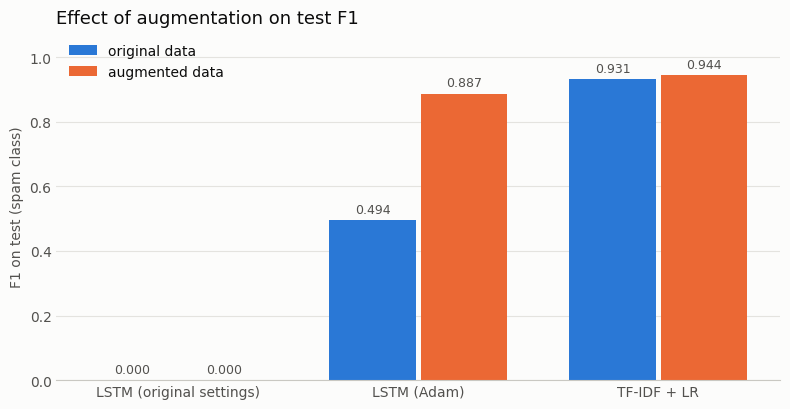

In [16]:
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

INK = "#0b0b0b"
MUTED = "#52514e"
SURFACE = "#fcfcfb"
COLORS = {"original data": "#2a78d6", "augmented data": "#eb6834"}

models = list(runs)
x = np.arange(len(models))
width = 0.36

fig, ax = plt.subplots(figsize=(8, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for k, data in enumerate(["original data", "augmented data"]):
    values = [runs[m][data]["f1"] for m in models]
    bars = ax.bar(x + (k - 0.5) * (width + 0.02), values, width, color=COLORS[data], label=data)
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in values], padding=3, color=MUTED, fontsize=9)
ax.set_xticks(x, models, color=INK)
ax.set_ylim(0, 1.08)
ax.set_ylabel("F1 on test (spam class)", color=MUTED)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c9c8c2")
ax.tick_params(colors=MUTED, length=0)
ax.legend(frameon=False, loc="upper left", labelcolor=INK)
ax.set_title("Effect of augmentation on test F1", loc="left", color=INK, fontsize=13)
fig.tight_layout()
fig.savefig("results/augmentation_f1.png", dpi=150, facecolor=SURFACE)
plt.show()

For the TF-IDF model augmentation gives a small gain: F1 0.931 to 0.944, all from recall (0.878 to 0.901) with precision unchanged. That's 3 more spam messages caught out of 131 in test, so I'd call it a modest effect. Typos, abbreviations and new numbers give the character n-grams a few more spellings of the same spam patterns.

In [17]:
from utils import save_metrics

metrics = save_metrics(
    "augmentation",
    {
        "train_size": len(df_train),
        "augmented_size": len(df_train_augmented),
        "train_spam_rate": round(float(Y_train.mean()), 4),
        "augmented_spam_rate": round(float(Y_train_augmented.mean()), 4),
        "policy": {
            "type": "MeanFieldPolicy",
            "sequence_length": 2,
            "n_per_original": 2,
            "keep_original": True,
            "tf_weights": dict(zip([f.name for f in tfs], tf_weights)),
        },
        "test_scores": {model: by_data for model, by_data in runs.items()},
        "lstm_adam_original_data_equal_updates": {"epochs": equal_epochs, **lstm_adam_equal_updates},
    },
)
print(list(metrics))

['dataset', 'labeling', 'augmentation']


## Summary

- I kept the original's WordNet synonym TFs and added three SMS-specific ones: abbreviation swaps, typos and number replacement.
- The mean field policy grew train from 3,619 to 8,569 messages.
- The original LSTM settings predict ham for everything on this imbalanced data. With Adam the LSTM works, and augmentation seems to help a lot, but a control with the same number of updates shows that gain came from extra training.
- For the TF-IDF model augmentation adds a small amount of recall.

Part 3 looks at slices: groups of messages where a model can do worse than its overall score suggests.